# P-1 Comparison: Random Forest vs KNN vs Saved LSTM

I will we be comparing each model on the P-1 channel using a 250 history window/10-strp tail alignment and the shared detection.py anomaly detector. I will see what intervals these models predict as anomalies and compare them. 

I will compare their execution time and estimate their monthly computing costs. 

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error


# Find the main repository folder
repo_root = Path.cwd().resolve()

if repo_root.name == "Models":
    repo_root = repo_root.parent

# Allow Python to import detection.py
sys.path.insert(0, str(repo_root))

from detection import (
    detect_anomalies,
    evaluate_event_detection,
    calculate_prediction_errors
)


## Load the P-1 Training and Test Data

In [5]:
data_dir = repo_root / "data" / "data"

p1_train = np.load(data_dir / "train" / "P-1.npy")
p1_test = np.load(data_dir / "test" / "P-1.npy")

print("Train shape:", p1_train.shape)
print("Test shape:", p1_test.shape)

Train shape: (2872, 25)
Test shape: (8505, 25)


# Build Random Forest Model for 250 History Windows

As in the paper I will also use 250 time steps as history. I will use the telemetry values and also the other 24 features in the P-1 channel as input in order to forecast the next telemtry value. Each input window is flattened into 6,250 values (250x25) and leave the last 10 tme steps out of the prediction targets as is done in the paper. 

In [6]:
history = 250
n_predictions = 10

def make_windows(data, history=250, n_predictions=10):
    X = []
    y = []

    for t in range(history, len(data) - n_predictions):

        # Previous 250 time steps, using all 25 columns
        window = data[t-history:t, :]

        # Flatten 250 x 25 into one long input vector
        X.append(window.flatten())

        # Predict the next value of P-1, column 0
        y.append(data[t, 0])

    return np.array(X), np.array(y)


X_train, y_train = make_windows(p1_train)
X_test, y_test = make_windows(p1_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2612, 6250)
y_train: (2612,)
X_test: (8245, 6250)
y_test: (8245,)


### Train and Predict with Random Forest Model and compare the predictions with the actual telemtry values


We fit the model on the training data, then we predict on the test data (X_test) and then find the error of these predictions on the actual telemtry values of the test data (y_test). 

In [7]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_predictions = rf.predict(X_test)

print(rf_predictions.shape)

(8245,)


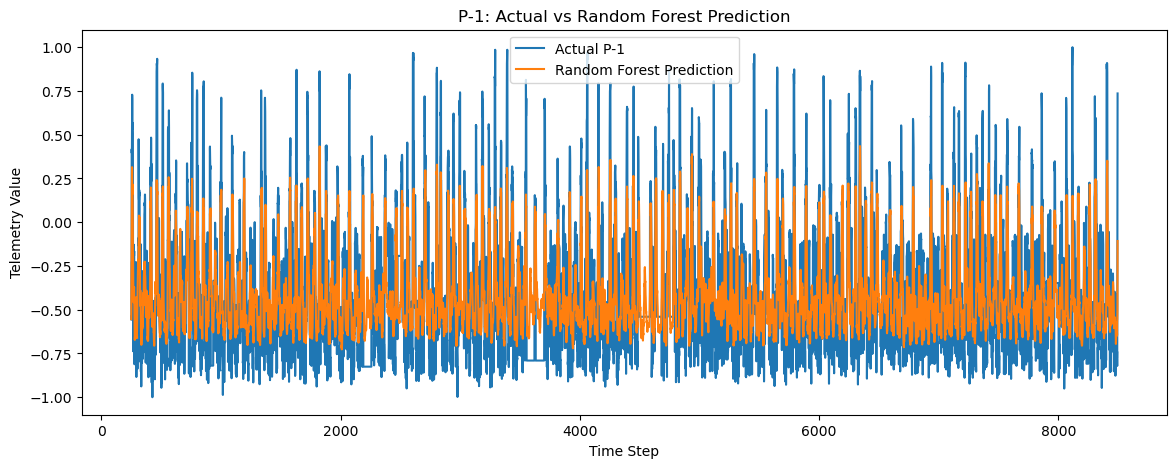

In [8]:
time = np.arange(250, 250 + len(y_test))

plt.figure(figsize=(14, 5))

plt.plot(time, y_test, label="Actual P-1")
plt.plot(time, rf_predictions, label="Random Forest Prediction")

plt.xlabel("Time Step")
plt.ylabel("Telemetry Value")
plt.title("P-1: Actual vs Random Forest Prediction")
plt.legend()

plt.show()

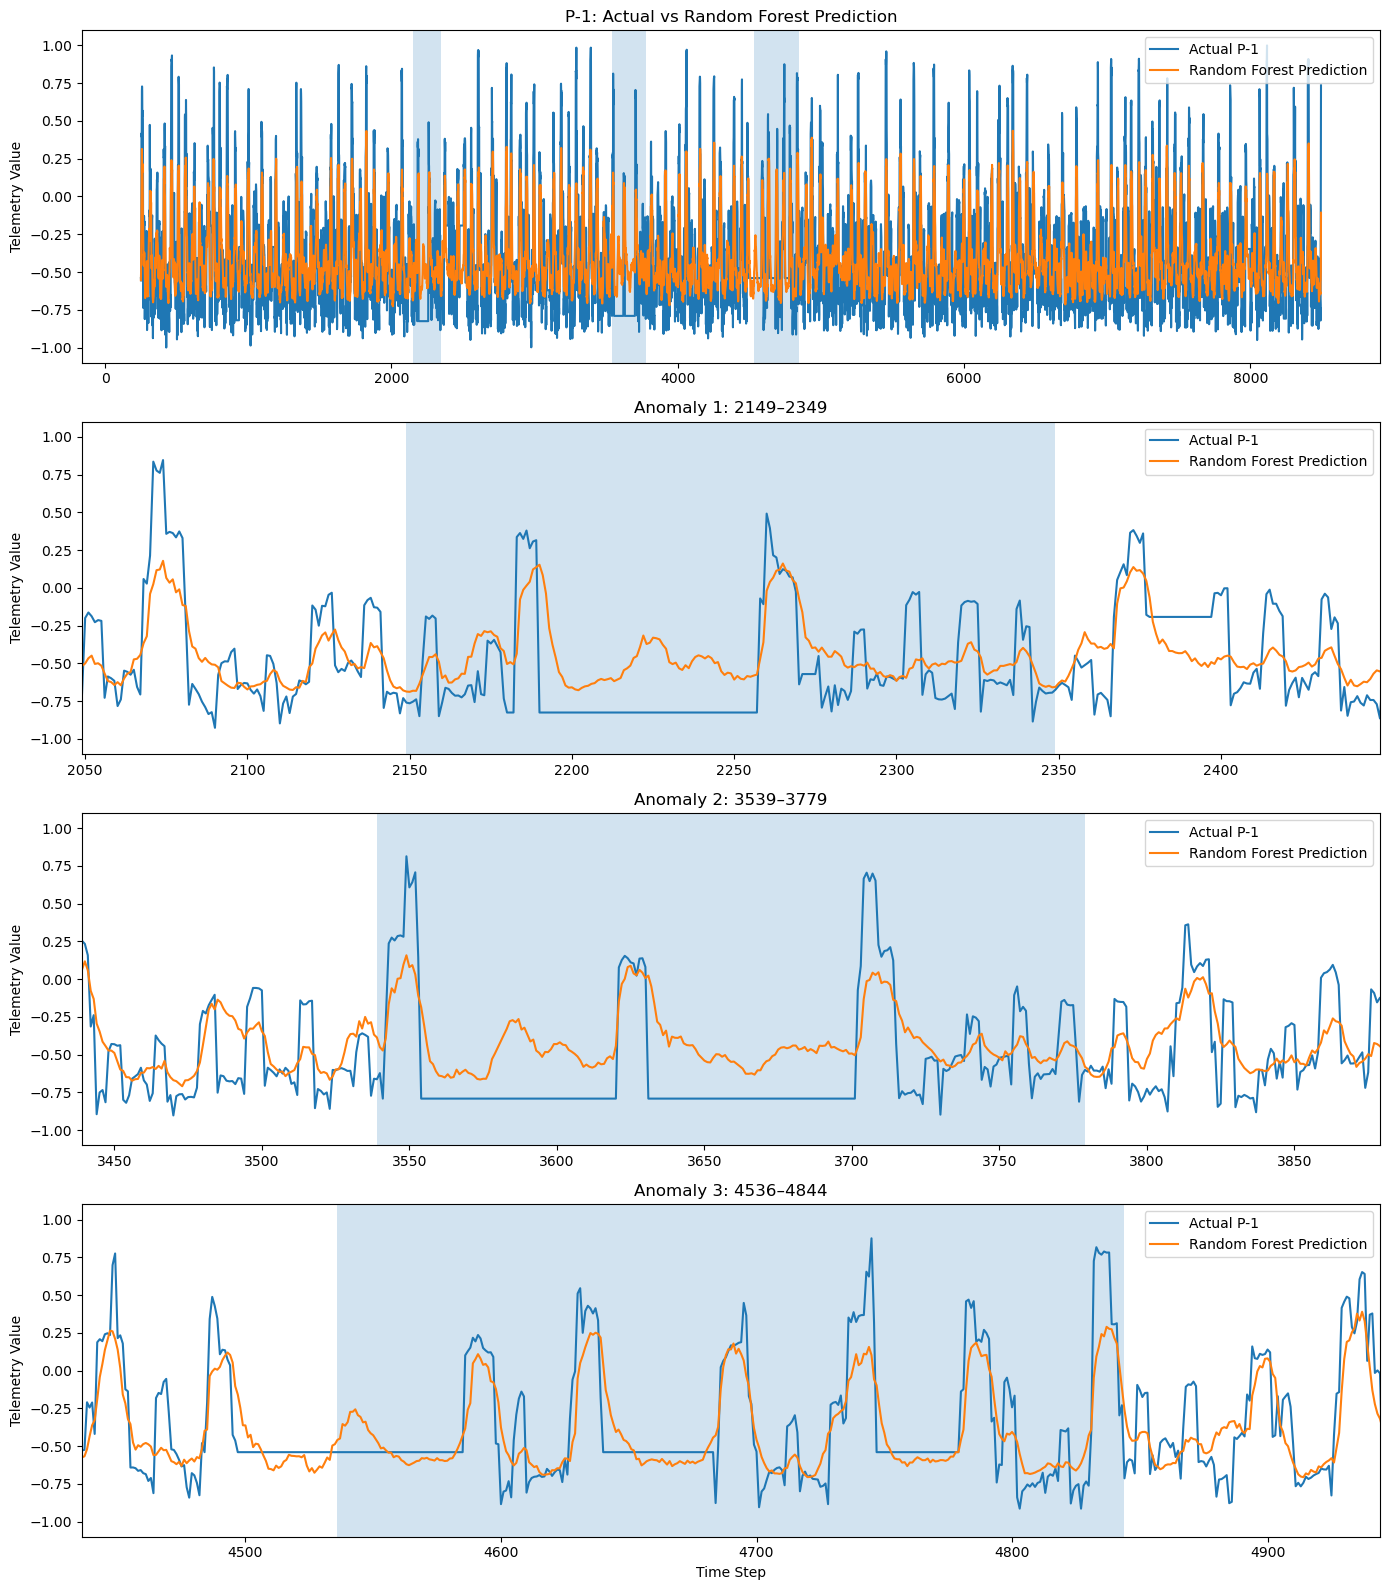

In [9]:
anomalies = [
    (2149, 2349),
    (3539, 3779),
    (4536, 4844)
]

fig, axes = plt.subplots(4, 1, figsize=(14, 16))

# Full P-1 series
axes[0].plot(time, y_test, label="Actual P-1")
axes[0].plot(time, rf_predictions, label="Random Forest Prediction")

for start, end in anomalies:
    axes[0].axvspan(start, end, alpha=0.2)

axes[0].set_title("P-1: Actual vs Random Forest Prediction")
axes[0].set_ylabel("Telemetry Value")
axes[0].legend()


# Zoom into each true anomaly
for i, (start, end) in enumerate(anomalies):

    axes[i+1].plot(time, y_test, label="Actual P-1")
    axes[i+1].plot(time, rf_predictions, label="Random Forest Prediction")

    axes[i+1].axvspan(start, end, alpha=0.2)

    # Show 100 timestamps before and after
    axes[i+1].set_xlim(start - 100, end + 100)

    axes[i+1].set_title(
        f"Anomaly {i+1}: {start}–{end}"
    )
    axes[i+1].set_ylabel("Telemetry Value")
    axes[i+1].legend()

axes[3].set_xlabel("Time Step")

plt.tight_layout()
plt.show()

### KNN Train and Predict

I will use K-nearest neighbors to predict telemetry values, note that for this model, I will only use the telemetry values to make prediction and will not use the other 24 features. 

#### Finding the best k value

I will hold the histort fixed at 250 but I will look for the "best" k. I will split the training data chornologically into 80% train and 20% validation sets to test different values of k that produces the lowest RMSE. We will train KNN on different values for k on the train and predict the validation set look at the RMSE for each. By best k, I mean I will take the k that has the lowest RMSE and will use this k for the KNN model. 

In [11]:
from sklearn.neighbors import KNeighborsRegressor

# --------------------------------------------------
# Recreate the original 1-column KNN experiment
# --------------------------------------------------

train_signal = p1_train[:, 0]
test_signal = p1_test[:, 0]

def make_knn_windows(series, history=250, n_predictions=10):
    X = []
    y = []

    for t in range(history, len(series) - n_predictions):
        X.append(series[t-history:t])
        y.append(series[t])

    return np.array(X), np.array(y)


X_train_knn, y_train_knn = make_knn_windows(train_signal)
X_test_knn, y_test_knn = make_knn_windows(test_signal)


# Split training data into training and validation sets
split = int(0.8 * len(X_train_knn))

X_fit = X_train_knn[:split]
X_val = X_train_knn[split:]

y_fit = y_train_knn[:split]
y_val = y_train_knn[split:]


# Try different values of k
k_values = range(1, 61)
rmses = []

for k in k_values:

    model = KNeighborsRegressor(
        n_neighbors=k,
        weights="distance"
    )

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    rmses.append(rmse)


# Find the k with the lowest RMSE
best_k = list(k_values)[np.argmin(rmses)]

print("Best k:", best_k)
print("Lowest RMSE:", min(rmses))


# Train the final KNN model
knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights="distance"
)

knn.fit(X_train_knn, y_train_knn)

knn_predictions = knn.predict(X_test_knn)



# --------------------------------------------------
# Load the paper's saved LSTM predictions
# --------------------------------------------------

paper_predictions = np.load(
    data_dir / "2018-05-19_15.00.10" / "y_hat" / "P-1.npy"
)

print("Random Forest:", rf_predictions.shape)
print("KNN:", knn_predictions.shape)
print("Paper LSTM:", paper_predictions.shape)
print("Actual:", y_test.shape)

Best k: 26
Lowest RMSE: 0.3619168207978163
Random Forest: (8245,)
KNN: (8245,)
Paper LSTM: (8245,)
Actual: (8245,)


## Plot Validation RMSE against k

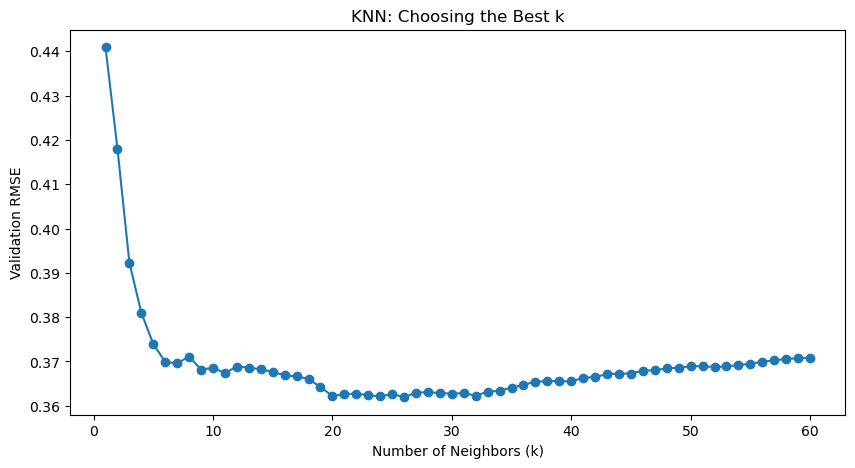

In [12]:

plt.figure(figsize=(10, 5))

plt.plot(k_values, rmses, marker="o")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation RMSE")
plt.title("KNN: Choosing the Best k")

plt.show()


## Compare predictions for KNN, Random Forest and saved LSTM

The plots below compare the actual P-1 measurements with KNN using k = 26, Random Forest, and the saved LSTM. I zoomed into the anamolies to see how they compare with one another. 

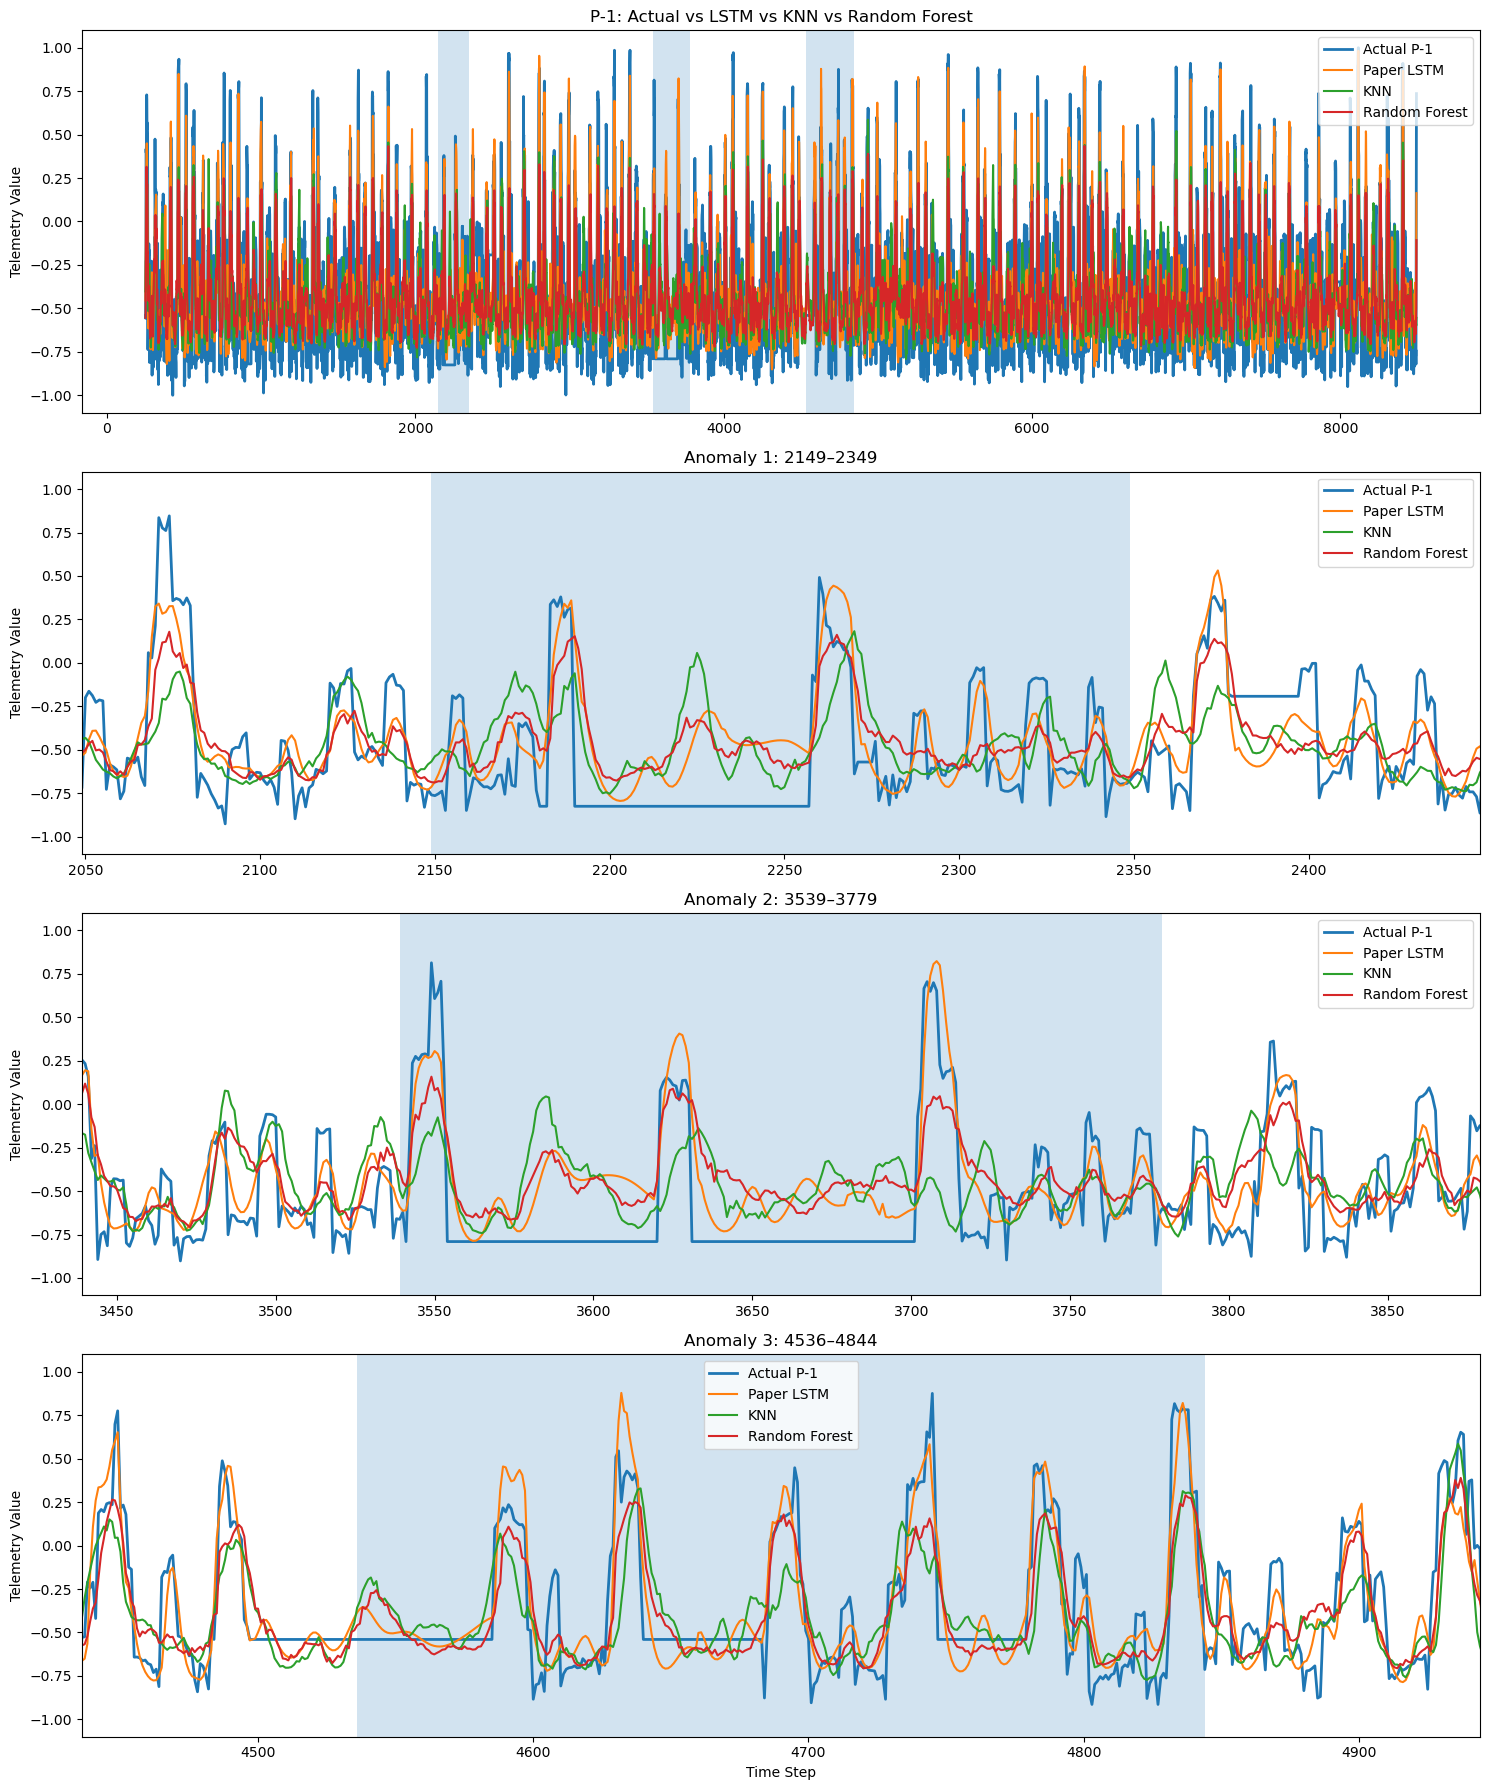

In [13]:
time = np.arange(250, 250 + len(y_test))

anomalies = [
    (2149, 2349),
    (3539, 3779),
    (4536, 4844)
]

fig, axes = plt.subplots(4, 1, figsize=(15, 18))


# ==================================================
# Full P-1 series
# ==================================================

axes[0].plot(
    time,
    y_test,
    label="Actual P-1",
    linewidth=2
)

axes[0].plot(
    time,
    paper_predictions,
    label="Paper LSTM"
)

axes[0].plot(
    time,
    knn_predictions,
    label="KNN"
)

axes[0].plot(
    time,
    rf_predictions,
    label="Random Forest"
)

for start, end in anomalies:
    axes[0].axvspan(start, end, alpha=0.2)

axes[0].set_title(
    "P-1: Actual vs LSTM vs KNN vs Random Forest"
)
axes[0].set_ylabel("Telemetry Value")
axes[0].legend()


# ==================================================
# Zoom into each anomaly
# ==================================================

for i, (start, end) in enumerate(anomalies):

    ax = axes[i + 1]

    ax.plot(
        time,
        y_test,
        label="Actual P-1",
        linewidth=2
    )

    ax.plot(
        time,
        paper_predictions,
        label="Paper LSTM"
    )

    ax.plot(
        time,
        knn_predictions,
        label="KNN"
    )

    ax.plot(
        time,
        rf_predictions,
        label="Random Forest"
    )

    # True anomaly region
    ax.axvspan(
        start,
        end,
        alpha=0.2
    )

    # Show some data before and after
    ax.set_xlim(
        start - 100,
        end + 100
    )

    ax.set_title(
        f"Anomaly {i+1}: {start}–{end}"
    )

    ax.set_ylabel("Telemetry Value")
    ax.legend()


axes[3].set_xlabel("Time Step")

plt.tight_layout()
plt.show()

## We will now take a look at the raw errors: error = $|y_{test} - y_{prediction}|$

I will calculate the raw errors for each model including the papers model and then plot the errors to compare them. 

In [14]:
rf_error = np.abs(y_test - rf_predictions)

knn_error = np.abs(y_test - knn_predictions)

paper_error = np.abs(y_test - paper_predictions)

print("Random Forest error:", rf_error.shape)
print("KNN error:", knn_error.shape)
print("Paper LSTM error:", paper_error.shape)

Random Forest error: (8245,)
KNN error: (8245,)
Paper LSTM error: (8245,)


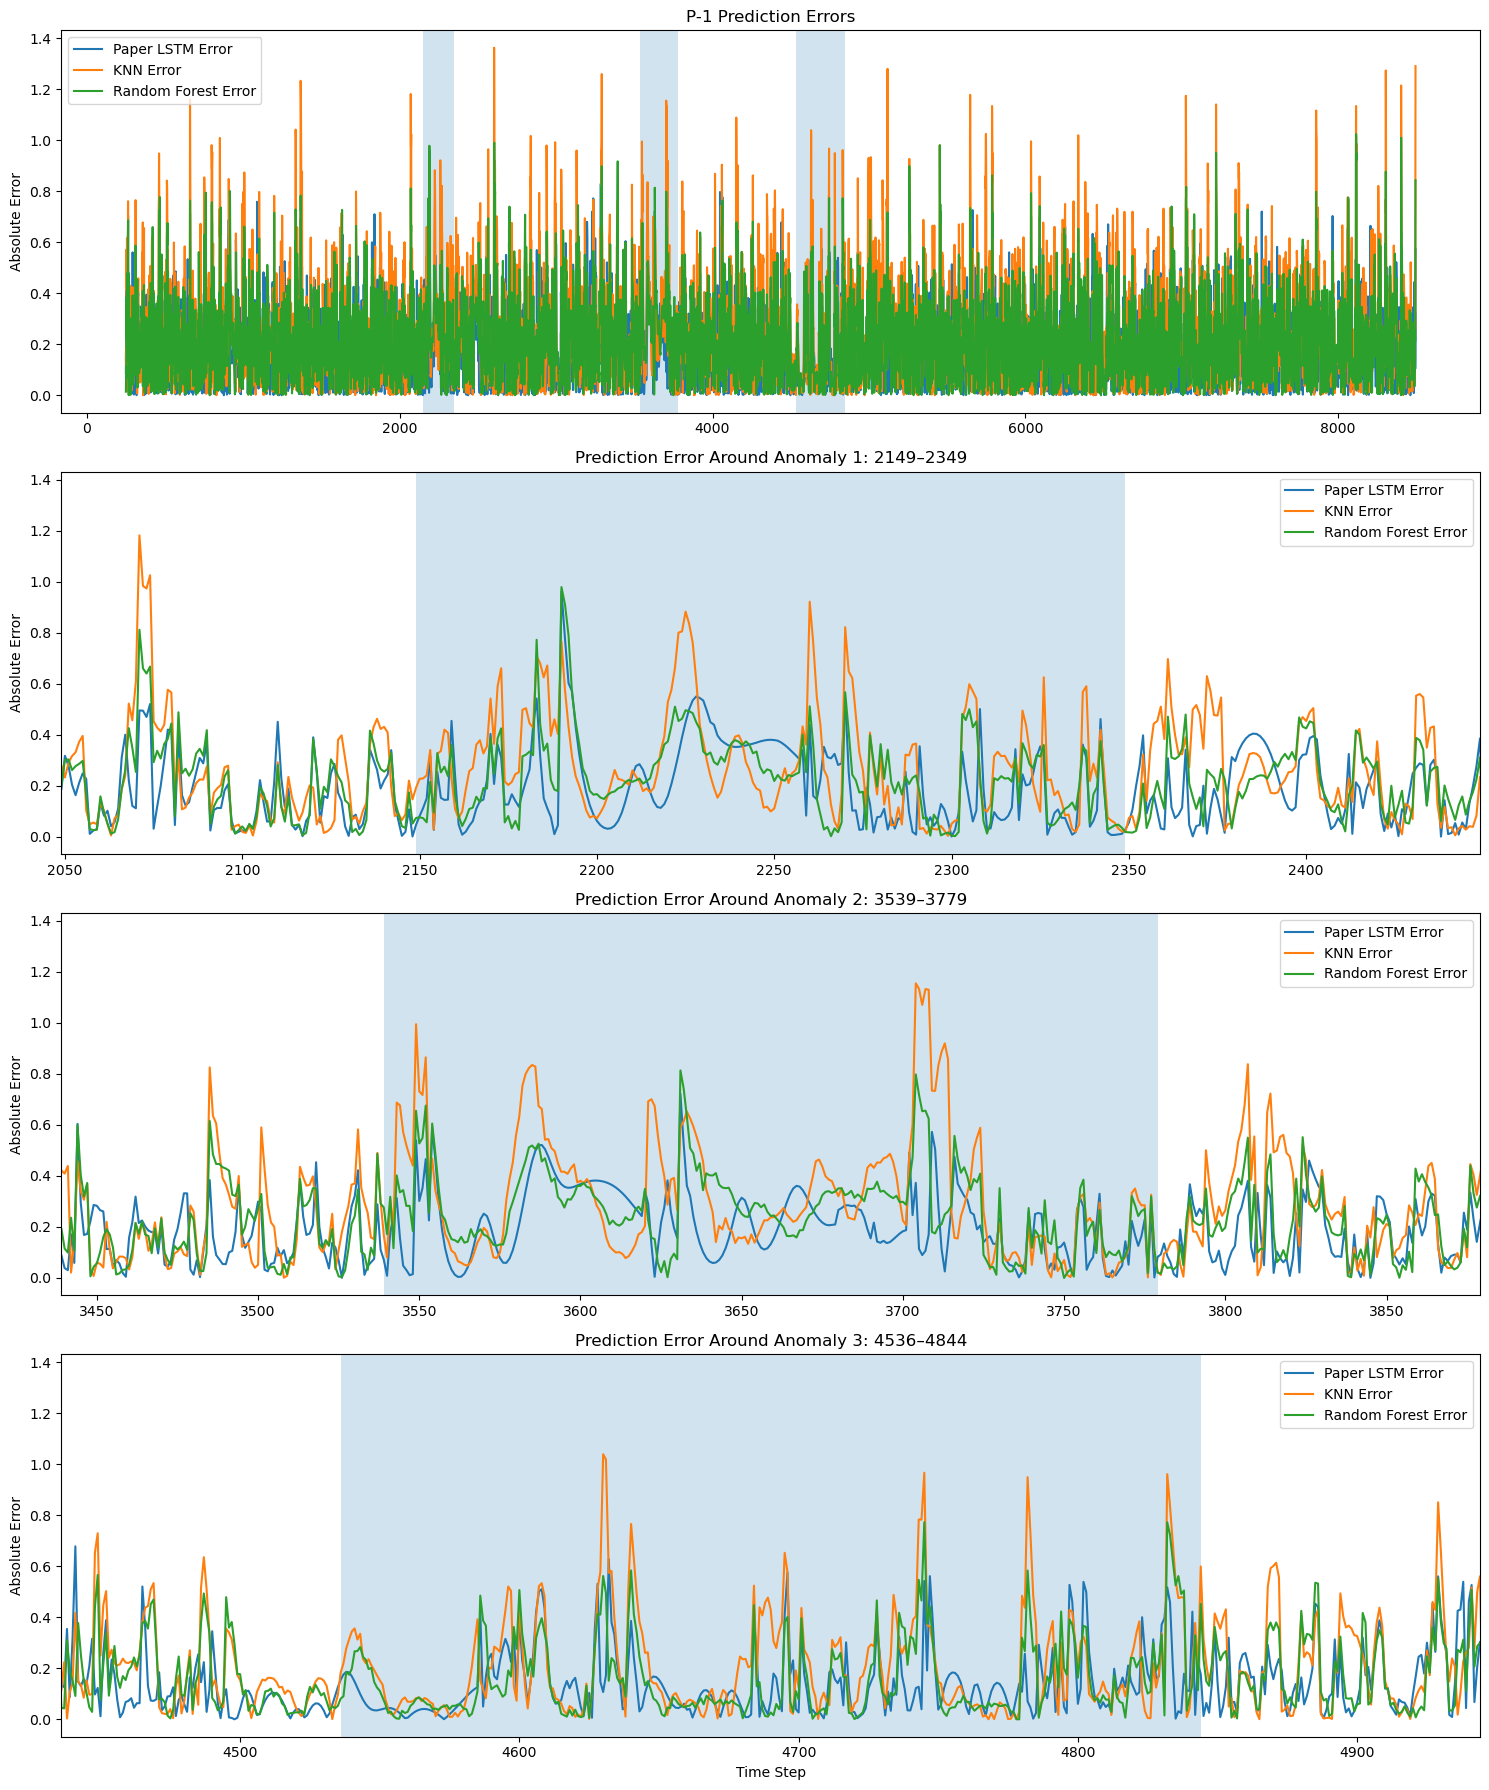

In [15]:
fig, axes = plt.subplots(4, 1, figsize=(15, 18))

# Full error series
axes[0].plot(time, paper_error, label="Paper LSTM Error")
axes[0].plot(time, knn_error, label="KNN Error")
axes[0].plot(time, rf_error, label="Random Forest Error")

for start, end in anomalies:
    axes[0].axvspan(start, end, alpha=0.2)

axes[0].set_title("P-1 Prediction Errors")
axes[0].set_ylabel("Absolute Error")
axes[0].legend()


# Zoom into each true anomaly
for i, (start, end) in enumerate(anomalies):

    ax = axes[i + 1]

    ax.plot(time, paper_error, label="Paper LSTM Error")
    ax.plot(time, knn_error, label="KNN Error")
    ax.plot(time, rf_error, label="Random Forest Error")

    ax.axvspan(start, end, alpha=0.2)

    ax.set_xlim(start - 100, end + 100)

    ax.set_title(
        f"Prediction Error Around Anomaly {i+1}: {start}–{end}"
    )

    ax.set_ylabel("Absolute Error")
    ax.legend()

axes[3].set_xlabel("Time Step")

plt.tight_layout()
plt.show()

## Smooth the errors with EWMA

Going to compare the smooth errors for each model. 

In [16]:
# Calculate raw and smoothed errors using detection.py

rf_error, rf_smooth_error = calculate_prediction_errors(
    actual=y_test,
    predictions=rf_predictions
)

knn_error, knn_smooth_error = calculate_prediction_errors(
    actual=y_test,
    predictions=knn_predictions
)

paper_error, paper_smooth_error = calculate_prediction_errors(
    actual=y_test,
    predictions=paper_predictions
)

print("Random Forest:", rf_smooth_error.shape)
print("KNN:", knn_smooth_error.shape)
print("Paper LSTM:", paper_smooth_error.shape)

Random Forest: (8245,)
KNN: (8245,)
Paper LSTM: (8245,)


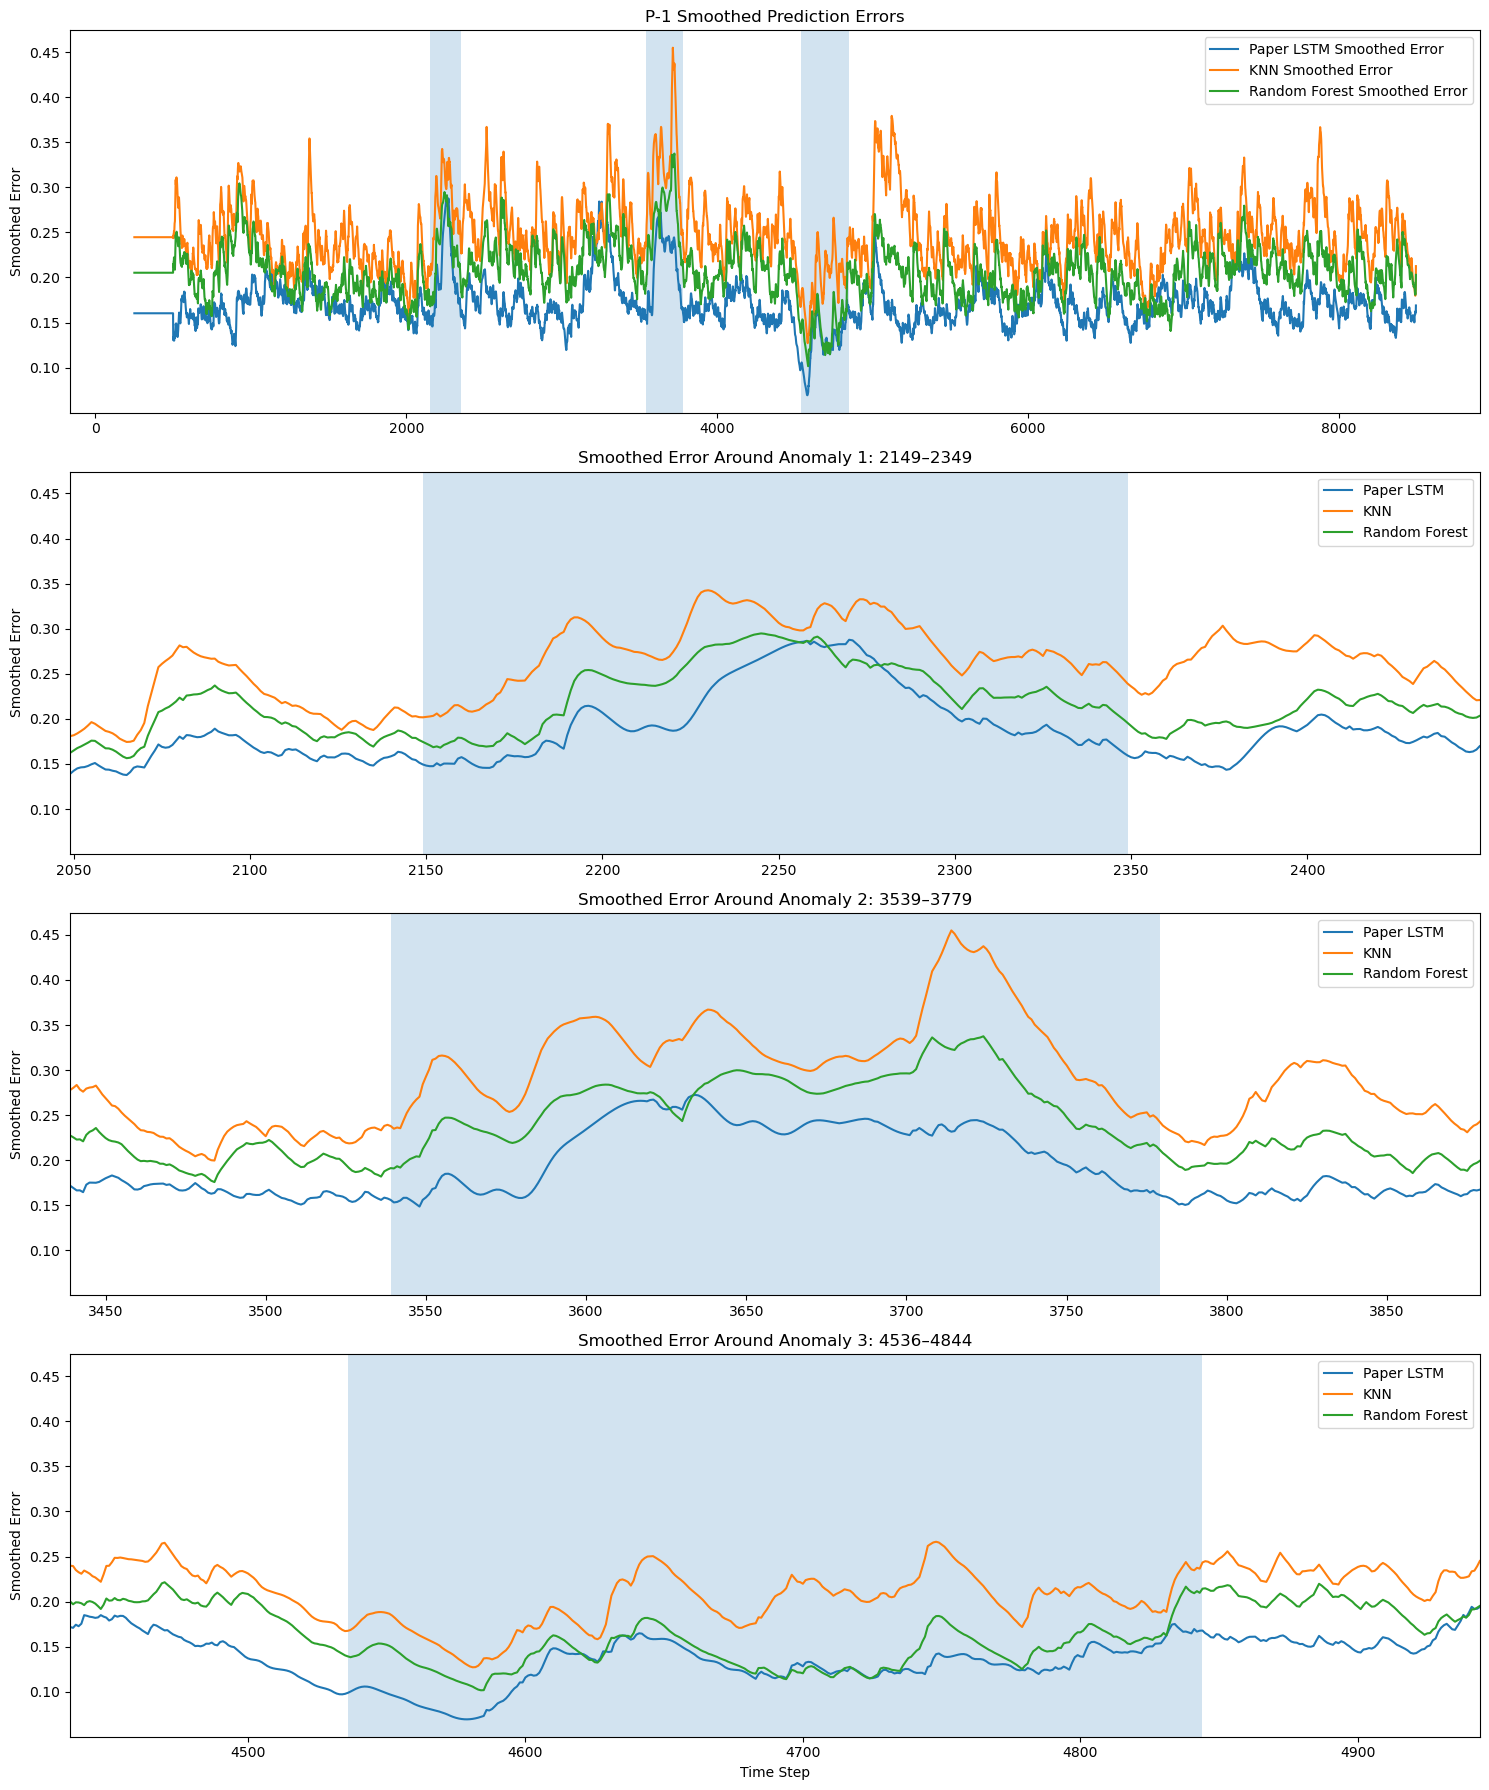

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(15, 18))

# Full smoothed-error series
axes[0].plot(time, paper_smooth_error, label="Paper LSTM Smoothed Error")
axes[0].plot(time, knn_smooth_error, label="KNN Smoothed Error")
axes[0].plot(time, rf_smooth_error, label="Random Forest Smoothed Error")

for start, end in anomalies:
    axes[0].axvspan(start, end, alpha=0.2)

axes[0].set_title("P-1 Smoothed Prediction Errors")
axes[0].set_ylabel("Smoothed Error")
axes[0].legend()


# Zoom into each anomaly
for i, (start, end) in enumerate(anomalies):

    ax = axes[i + 1]

    ax.plot(time, paper_smooth_error, label="Paper LSTM")
    ax.plot(time, knn_smooth_error, label="KNN")
    ax.plot(time, rf_smooth_error, label="Random Forest")

    ax.axvspan(start, end, alpha=0.2)

    ax.set_xlim(start - 100, end + 100)

    ax.set_title(
        f"Smoothed Error Around Anomaly {i+1}: {start}–{end}"
    )

    ax.set_ylabel("Smoothed Error")
    ax.legend()

axes[3].set_xlabel("Time Step")

plt.tight_layout()
plt.show()

# Detect the anomlies using the KNN model

Recall that the KNN model only uses the telemetry values as input to predict the next telemetry value. 

In [18]:

# Detect anomaly regions using KNN

knn_result = detect_anomalies(
    test_data=p1_test,
    predictions=knn_predictions
)

knn_detected_ranges = knn_result["detected_intervals"]

print(knn_detected_ranges)


[(3680, 3749), (4520, 4659)]


# Detect the anomaly regions using Random Forest

Recall that the Random Forest model will use the telemtry values and also the other 24 features as inputs in order to predict the next telemetry value. 



In [19]:
rf_result = detect_anomalies(
    test_data=p1_test,
    predictions=rf_predictions
)

rf_detected_ranges = rf_result["detected_intervals"]

print(rf_result["detected_intervals"])


[(816, 1043), (2128, 2349), (4520, 4729)]


# Detect the anomaly regions using the LSTM paper errors 

I want to make sure I get the correct anomalies from the papers. 

In [20]:
# Detect anomalies using the paper's saved LSTM predictions
paper_result = detect_anomalies(
    test_data=p1_test,
    predictions=paper_predictions
)

paper_detected_ranges = paper_result["detected_intervals"]

print("Detected anomaly regions:")

for region in paper_detected_ranges:
    print(region)



Detected anomaly regions:
(2130, 2349)
(3190, 3329)
(3540, 3679)
(4520, 4589)


## Calculate True Positives, False Positives and False Negatives on each model

- TP (True Postives): A labeled event overlaps at least one alert
- FP (False Postive): An alert overlaps no labeled event. 
- FN (False Negative): A labeled event overlaps no alert. 


The metrics used are: 

$$\text{Precision} = \frac{TP}{TP+FP}$$

$$\text{Recall} = \frac{TP}{TP+FN}$$

and $$F_1 = 2\frac{\text{Precision}\times \text{ Recall}}{\text{Precision} + \text{Recall} }$$

In [21]:
# Evaluate anomaly detection against the three known P-1 events

labeled_intervals = sorted(anomalies)

# Store detected anomaly regions
detections = {
    "KNN": knn_detected_ranges,
    "Random Forest": rf_detected_ranges,
    "Saved LSTM": paper_detected_ranges
}

# Evaluate each model
evaluations = {}

for name, regions in detections.items():
    evaluations[name] = evaluate_event_detection(
        regions, labeled_intervals
    )


# Create the comparison table
event_comparison = pd.DataFrame([
    {
        "Model": name,
        "Alert Intervals": len(detections[name]),
        "TP": result["TP"],
        "FP": result["FP"],
        "FN": result["FN"],
        "Precision": result["precision"],
        "Recall": result["recall"],
        "F1": result["f1"]
    }
    for name, result in evaluations.items()
]).set_index("Model")

display(event_comparison)

,Alert Intervals,TP,FP,FN,Precision,Recall,F1
Model,,,,,,,
KNN,2,2,0,1,1.000000,0.666667,0.800000
Random Forest,3,2,1,1,0.666667,0.666667,0.666667
Saved LSTM,4,3,1,0,0.750000,1.000000,0.857143


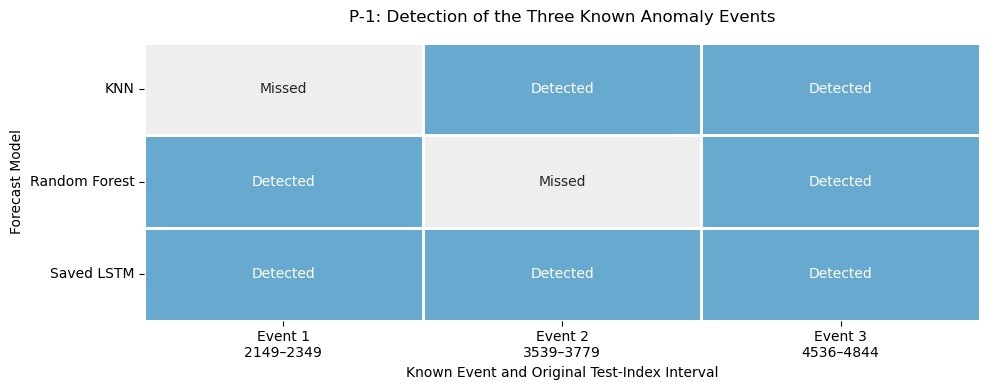

In [22]:
# Models and their detected anomaly regions
models = {
    "KNN": knn_detected_ranges,
    "Random Forest": rf_detected_ranges,
    "Saved LSTM": paper_detected_ranges
}

# Sort the actual P-1 anomaly sequences
events = sorted(anomalies)

# Check which anomalies each model detected
coverage = []

for name, regions in models.items():
    row = []

    for start, end in events:
        found = any(a <= end and b >= start for a, b in regions)
        row.append(int(found))

    coverage.append(row)

# Create the comparison table
event_names = [
    f"Event {i+1}\n{start}–{end}"
    for i, (start, end) in enumerate(events)
]

event_coverage = pd.DataFrame(
    coverage,
    index=models.keys(),
    columns=event_names
)

annotations = np.where(
    event_coverage.to_numpy() == 1,
    "Detected",
    "Missed"
)

# Plot the heatmap
plt.close("all")
fig, ax = plt.subplots(figsize=(10, 4))

sns.heatmap(
    event_coverage,
    annot=annotations,
    fmt="",
    cmap=["#eeeeee", "#67a9cf"],
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=2,
    linecolor="white",
    ax=ax
)

ax.set_title("P-1: Detection of the Three Known Anomaly Events", pad=15)
ax.set_xlabel("Known Event and Original Test-Index Interval")
ax.set_ylabel("Forecast Model")

ax.tick_params(axis="x", labelrotation=0)
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()


# Computation cost benchmark

This section estimates the operational computing cost of for the Random Forest and KNN models using the same benchmarking and cloud-cost assumptions used in Rios_Forecasting_Cost_Comparison.ipynb. 

## Forecasting Functions 

Make functions that make predictions using KNN and Random Forest regressor and check that they produce the same values


In [ ]:
# Prepare forecasting operations for runtime comparison

def generate_knn_forecasts(test_data, fitted_knn):

    X, y = make_knn_windows(test_data[:, 0])

    return fitted_knn.predict(X)


def generate_rf_forecasts(test_data, fitted_rf):

    X, y = make_windows(test_data)

    return fitted_rf.predict(X)


# Check that the functions reproduce our existing forecasts
knn_check = generate_knn_forecasts(p1_test, knn)

rf_check = generate_rf_forecasts(p1_test, rf)

assert np.allclose(knn_check, knn_predictions)
assert np.allclose(rf_check, rf_predictions)


## Measure Run time

How long does it take a computer to process the same 8245 readings using each forecasting method. 

In [24]:

import timeit
from threadpoolctl import threadpool_limits

# Forecasting operations
forecast_operations = {
    "KNN": lambda: generate_knn_forecasts(p1_test, knn),
    "Random Forest": lambda: generate_rf_forecasts(p1_test, rf)
}

# Existing predictions
existing_predictions = {
    "KNN": knn_predictions,
    "Random Forest": rf_predictions
}


def run_detection(predictions):

    return detect_anomalies(
        test_data=p1_test,
        predictions=predictions
    )


# Run forecasting and detection together
def run_complete_pipeline(forecast_operation):

    predictions = forecast_operation()

    return run_detection(predictions)


runtime_rows = []

# Use one CPU worker for the benchmark
original_n_jobs = rf.n_jobs
rf.n_jobs = 1

try:
    with threadpool_limits(limits=1):

        for name, forecast_operation in forecast_operations.items():

            predictions = existing_predictions[name]

            operations = {
                "Forecast generation": forecast_operation,
                "Detection only": lambda p=predictions: run_detection(p),
                "Complete pipeline": lambda f=forecast_operation: run_complete_pipeline(f)
            }

            for stage, operation in operations.items():

                # Warm-up run
                operation()

                timer = timeit.Timer(operation)

                # Determine how many calls to time
                calls_per_repeat, _ = timer.autorange()

                # Repeat measurements seven times
                elapsed = np.asarray(
                    timer.repeat(repeat=7, number=calls_per_repeat)
                )

                milliseconds = elapsed / calls_per_repeat * 1000

                runtime_rows.append({
                    "forecast source": name,
                    "stage": stage,
                    "calls per repeat": calls_per_repeat,
                    "median ms": np.median(milliseconds),
                    "25th percentile ms": np.percentile(milliseconds, 25),
                    "75th percentile ms": np.percentile(milliseconds, 75)
                })

finally:
    rf.n_jobs = original_n_jobs

runtime_results = pd.DataFrame(runtime_rows)

display(runtime_results)


,forecast source,stage,calls per repeat,median ms,25th percentile ms,75th percentile ms
0,KNN,Forecast generation,1,394.453750,394.298937,395.864250
1,KNN,Detection only,2,134.502000,134.228187,135.052052
2,KNN,Complete pipeline,1,530.315250,529.539792,530.970166
3,Random Forest,Forecast generation,1,1118.981042,1112.741959,1142.887583
4,Random Forest,Detection only,2,177.262084,172.609896,180.401177
5,Random Forest,Complete pipeline,1,1300.125083,1273.343438,1300.880854


## Compare Execution times 

Using the values above, the graphs below show the time needed in milliseconds to execute the 8245 values

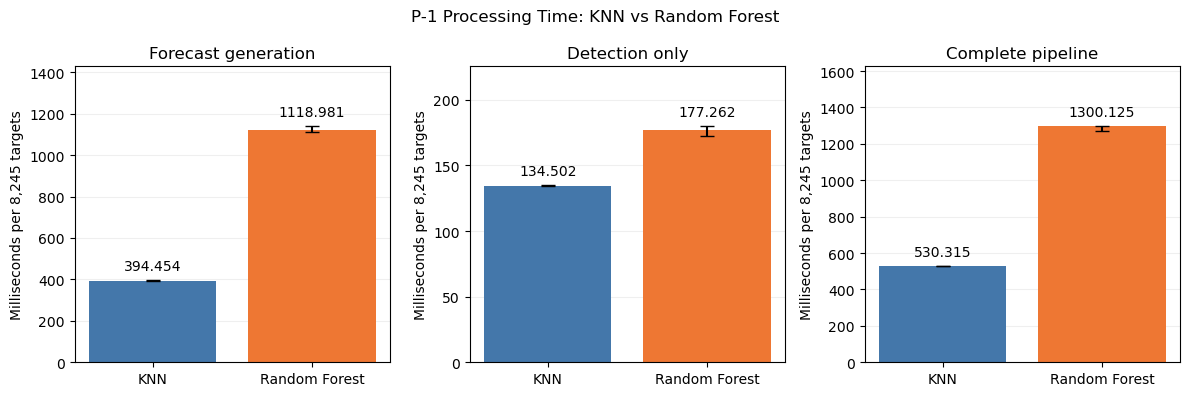

In [25]:

from pathlib import Path
import matplotlib.pyplot as plt

# Use our measured runtime results
runtime_reference = runtime_results.rename(columns={
    "forecast source": "method",
    "median ms": "median_ms",
    "25th percentile ms": "q25_ms",
    "75th percentile ms": "q75_ms"
}).copy()

runtime_reference["channel"] = "P-1"
runtime_reference["evaluated_targets"] = len(y_test)
runtime_reference["benchmark_run"] = 1

# Save figures and tables
results_dir = Path("results") / "forecasting_cost_comparison"
results_dir.mkdir(parents=True, exist_ok=True)

colors = {"KNN": "#4477AA", "Random Forest": "#EE7733"}

stages = [
    "Forecast generation",
    "Detection only",
    "Complete pipeline"
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, stage in zip(axes, stages):

    subset = (
        runtime_reference.loc[runtime_reference["stage"] == stage]
        .set_index("method")
        .loc[["KNN", "Random Forest"]]
    )

    medians = subset["median_ms"].to_numpy()

    # Interquartile range
    error_bars = np.vstack([
        medians - subset["q25_ms"].to_numpy(),
        subset["q75_ms"].to_numpy() - medians
    ])

    bars = ax.bar(
        subset.index,
        medians,
        color=[colors[name] for name in subset.index],
        yerr=error_bars,
        capsize=5
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.3f}" for value in medians],
        padding=5
    )

    ax.set_title(stage)
    ax.set_ylabel("Milliseconds per 8,245 targets")
    ax.set_ylim(0, subset["q75_ms"].max() * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("P-1 Processing Time: KNN vs Random Forest")
fig.tight_layout()

fig.savefig(
    results_dir / "runtime_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# Illustrative AWS Fargate cost scenario

To keep the group comparison consistent, this section uses the same deployment assumptions as Diego's cost notebook.

The official [AWS Fargate pricing page](https://aws.amazon.com/fargate/pricing/) lists, under **Pricing Examples → Example 1**, Linux/x86 rates for US East (N. Virginia) of:

- **$0.000011244 per vCPU-second**
- **$0.000001235 per GB-second**

AWS states that Linux Fargate duration is billed per second with a **1-minute minimum**, rounded up to the nearest whole second.

## Assumptions

- Allocate **1 vCPU and 2 GB memory**.
- Process **1,000 P-1-sized batches per day**.
- Each batch contains the same **8,245 evaluated targets**.
- Use one task per day that processes the 1,000 batches sequentially.
- Use **30 days per month**.
- Add **30 seconds of startup/other overhead** per daily task.
- Examine cloud runtimes equal to **0.5×, 1×, and 2×** the measured local complete-pipeline runtime.
- Exclude training, model selection, storage, networking, logging, taxes, and human alert investigation.

This is an illustrative deployment scenario rather than a measured AWS deployment.

For measured complete-pipeline batch runtime $t_{\text{batch}}$, in seconds, and cloud-to-local runtime multiplier $s$,

$$
t_{\text{daily}} = 1000\,t_{\text{batch}}\,s + 30.
$$

The estimated monthly computing cost is

$$
C_{\text{month}} = 30 \times \max\left(60,\left\lceil t_{\text{daily}}\right\rceil\right) \times \left(r_{\text{CPU}} + 2r_{\text{memory}}\right).
$$

The maximum and ceiling implement the 60-second minimum billed duration and whole-second rounding.

In [26]:
# Calculate AWS Fargate cost estimates

# Published Fargate Linux/x86 example rates, US East (N. Virginia)
cpu_price_per_second = 0.000011244
memory_price_per_gb_second = 0.000001235

allocated_vcpus = 1
allocated_memory_gb = 2

batches_per_day = 1000
days_per_month = 30
startup_seconds_per_day = 30

runtime_multipliers = [0.5, 1.0, 2.0]

# Calculate price per second
allocated_price_per_second = (
    allocated_vcpus * cpu_price_per_second
    + allocated_memory_gb * memory_price_per_gb_second
)

# Complete pipeline runtimes in seconds
pipeline_times = (
    runtime_reference.loc[
        runtime_reference["stage"] == "Complete pipeline"
    ].set_index("method")["median_ms"] / 1000
)

cost_rows = []

for multiplier in runtime_multipliers:

    for method, batch_seconds in pipeline_times.items():

        processing_seconds = (
            batches_per_day * batch_seconds * multiplier
        )

        daily_task_seconds = (
            processing_seconds + startup_seconds_per_day
        )

        # Minimum billing duration of 60 seconds
        billed_seconds_per_day = max(
            60, int(np.ceil(daily_task_seconds))
        )

        monthly_cost = (
            billed_seconds_per_day
            * days_per_month
            * allocated_price_per_second
        )

        cost_rows.append({
            "method": method,
            "runtime multiplier": multiplier,
            "processing seconds per day": processing_seconds,
            "billed seconds per day": billed_seconds_per_day,
            "estimated monthly USD": monthly_cost
        })

cost_estimates = pd.DataFrame(cost_rows)

display(cost_estimates.round(4))

# Cost if the task runs continuously
always_running_monthly_cost = (
    days_per_month * 24 * 3600 * allocated_price_per_second
)

print(
    "Same allocation running continuously for 30 days:",
    f"${always_running_monthly_cost:.2f}"
)


,method,runtime multiplier,processing seconds per day,billed seconds per day,estimated monthly USD
0,KNN,0.5,265.1576,296,0.1218
1,Random Forest,0.5,650.0625,681,0.2802
2,KNN,1.0,530.3152,561,0.2308
3,Random Forest,1.0,1300.1251,1331,0.5476
4,KNN,2.0,1060.6305,1091,0.4489
5,Random Forest,2.0,2600.2502,2631,1.0824


Same allocation running continuously for 30 days: $35.55


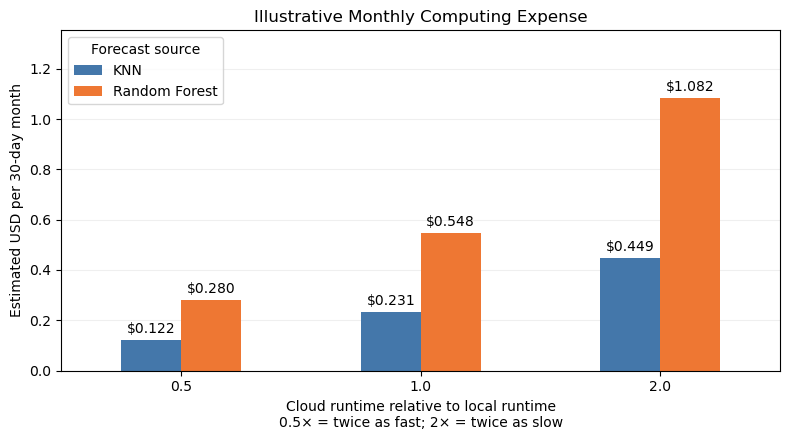

In [27]:
# Plot estimated monthly computing costs

cost_plot = (
    cost_estimates.pivot(
        index="runtime multiplier",
        columns="method",
        values="estimated monthly USD"
    ).reindex(columns=["KNN", "Random Forest"])
)

ax = cost_plot.plot.bar(
    figsize=(8, 4.5),
    color=[colors["KNN"], colors["Random Forest"]],
    rot=0
)

for container in ax.containers:
    ax.bar_label(container, fmt="$%.3f", padding=3)

ax.set_title("Illustrative Monthly Computing Expense")

ax.set_xlabel(
    "Cloud runtime relative to local runtime\n"
    "0.5× = twice as fast; 2× = twice as slow"
)

ax.set_ylabel("Estimated USD per 30-day month")
ax.set_ylim(0, cost_plot.to_numpy().max() * 1.25)
ax.legend(title="Forecast source")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    results_dir / "cost_scenarios.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# Save numerical results
runtime_reference.to_csv(
    results_dir / "runtime_results.csv", index=False
)

cost_estimates.to_csv(
    results_dir / "computing_cost_scenarios.csv", index=False
)

event_comparison.to_csv(
    results_dir / "event_detection_comparison.csv"
)
